In [ ]:

!pip install pandas numpy matplotlib seaborn scipy openpyxl statsmodels --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')


plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style("whitegrid")
sns.set_palette("Set2")

print("✅ All libraries loaded successfully!")
print("📁 Now upload your file...")


from google.colab import files
uploaded = files.upload()

import io
file_name = list(uploaded.keys())[0]
print(f"\n✅ File uploaded: {bihar_Migration.csv}")

✅ All libraries loaded successfully!
📁 Now upload your file...


In [ ]:

file_name = list(uploaded.keys())[0]
print(f"\n✅ File uploaded: {file_name}")
print(f"📦 File size: {len(uploaded[file_name]) / 1024 / 1024:.2f} MB")


✅ File uploaded: bihar_Migration (1).csv
📦 File size: 4.66 MB


In [ ]:

file_name = 'bihar_Migration (1).csv'

df_raw = pd.read_csv(file_name, encoding='utf-8', low_memory=False)


print("=" * 55)
print("📊 DATASET OVERVIEW")
print("=" * 55)
print(f"Total Rows    : {df_raw.shape[0]:,}")
print(f"Total Columns : {df_raw.shape[1]}")


print("\n📋 COLUMN NAMES:")
for i, col in enumerate(df_raw.columns):
    print(f"  [{i}] {col}")


print("\n🔍 FIRST 3 ROWS:")
display(df_raw.head(3))


print("\n🧬 DATA TYPES:")
print(df_raw.dtypes)


print("\n❓ MISSING VALUES PER COLUMN:")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "✅ No missing values found!")

In [ ]:

df_raw = pd.read_csv('bihar_Migration (1).csv', encoding='utf-8',
                     low_memory=False, header=None)


header_rows = df_raw.iloc[0:4]
print("📋 Raw header rows:")
display(header_rows)

📋 Raw header rows:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,"D-5: MIGRANTS BY PLACE OF LAST RESIDENCE, AGE,...",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
1,Table name,State,District,Area Name,Place of,Duration of,Age-group,Last,Total migrants,NaN,NaN,Reason for migration,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,enumeration,residence,NaN,residence,NaN,NaN,NaN,Work/Employment,NaN,NaN,Business,NaN,NaN,Education,NaN,NaN,Marriage,NaN,NaN,Moved after birth,NaN,NaN,Moved with household,NaN,NaN,Others,NaN,NaN
3,NaN,NaN,NaN,NaN,Total/Rural/Urban,NaN,NaN,Total/Rural/Urban,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females,Persons,Males,Females


In [ ]:


col_names = [
    'Table_Name',
    'State',
    'District',
    'Area_Name',
    'Place_of_Enumeration',
    'Duration_of_Residence',
    'Age_Group',
    'Last_Residence',
    'Total_Persons', 'Total_Males', 'Total_Females'
    'Work_Persons', 'Work_Males', 'Work_Females',
    'Business_Persons', 'Business_Males', 'Business_Females',
    'Education_Persons', 'Education_Males', 'Education_Females',
    'Marriage_Persons', 'Marriage_Males', 'Marriage_Females',
    'Birth_Persons', 'Birth_Males', 'Birth_Females',
    'Household_Persons', 'Household_Males', 'Household_Females',

    'Others_Persons', 'Others_Males', 'Others_Females'
]
df_raw2 = pd.read_csv('bihar_Migration (1).csv', encoding='utf-8',
                      low_memory=False, header=None, skiprows=5)

df_raw2.columns = col_names

print(f"✅ Shape after skipping headers: {df_raw2.shape}")
print("\n🔍 First 5 rows:")
display(df_raw2.head())

print("\n📌 Unique values in 'State' column:")
print(df_raw2['State'].dropna().unique()[:20])

print("\n📌 Unique values in 'Place_of_Enumeration':")
print(df_raw2['Place_of_Enumeration'].dropna().unique())

✅ Shape after skipping headers: (33348, 32)

🔍 First 5 rows:


,Table_Name,State,District,Area_Name,Place_of_Enumeration,Duration_of_Residence,Age_Group,Last_Residence,Total_Persons,Total_Males,Total_Females,Work_Persons,Work_Males,Work_Females,Business_Persons,Business_Males,Business_Females,Education_Persons,Education_Males,Education_Females,Marriage_Persons,Marriage_Males,Marriage_Females,Birth_Persons,Birth_Males,Birth_Females,Household_Persons,Household_Males,Household_Females,Others_Persons,Others_Males,Others_Females
0,D1005,10.0,0.0,State - BIHAR,Total,All durations of residence,All ages,Total,27244869.0,3837402.0,23407467.0,706557.0,539176.0,167381.0,84087.0,39258.0,44829.0,121765.0,73883.0,47882.0,20440337.0,380142.0,20060195.0,292698.0,176827.0,115871.0,1268122.0,605293.0,662829.0,4331303.0,2022823.0,2308480.0
1,D1005,10.0,0.0,State - BIHAR,Total,All durations of residence,0-4,Total,483202.0,245247.0,237955.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,78875.0,41083.0,37792.0,68267.0,35506.0,32761.0,336060.0,168658.0,167402.0
2,D1005,10.0,0.0,State - BIHAR,Total,All durations of residence,5-9,Total,574208.0,298170.0,276038.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,56674.0,29731.0,26943.0,104019.0,55522.0,48497.0,413515.0,212917.0,200598.0
3,D1005,10.0,0.0,State - BIHAR,Total,All durations of residence,10-14,Total,669550.0,325421.0,344129.0,4358.0,2454.0,1904.0,905.0,458.0,447.0,30001.0,13917.0,16084.0,16451.0,374.0,16077.0,47278.0,24701.0,22577.0,135152.0,71388.0,63764.0,435405.0,212129.0,223276.0
4,D1005,10.0,0.0,State - BIHAR,Total,All durations of residence,15-19,Total,1271679.0,294340.0,977339.0,11880.0,5813.0,6067.0,2525.0,705.0,1820.0,26321.0,15834.0,10487.0,674137.0,8348.0,665789.0,31031.0,18054.0,12977.0,131260.0,70122.0,61138.0,394525.0,175464.0,219061.0



📌 Unique values in 'State' column:
[10.]

📌 Unique values in 'Place_of_Enumeration':
['Total' 'Rural' 'Urban']


In [ ]:


df = df_raw2.copy()
df.drop(columns=['Table_Name', 'State'], inplace=True)

df['Area_Name'] = df['Area_Name'].astype(str).str.strip()
df['District'] = pd.to_numeric(df['District'], errors='coerce')

numeric_cols = [
    'Total_Persons', 'Total_Males', 'Total_Females',
    'Work_Persons', 'Work_Males', 'Work_Females',
    'Business_Persons', 'Business_Males', 'Business_Females',
    'Education_Persons', 'Education_Males', 'Education_Females',
    'Marriage_Persons', 'Marriage_Males', 'Marriage_Females',
    'Birth_Persons', 'Birth_Males', 'Birth_Females',
    'Household_Persons', 'Household_Males', 'Household_Females',
    'Others_Persons', 'Others_Males', 'Others_Females'
]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')


df['Place_of_Enumeration'] = df['Place_of_Enumeration'].astype(str).str.strip()
df['Duration_of_Residence'] = df['Duration_of_Residence'].astype(str).str.strip()
df['Age_Group'] = df['Age_Group'].astype(str).str.strip()
df['Last_Residence'] = df['Last_Residence'].astype(str).str.strip()

df = df.dropna(subset=['Total_Persons'])

df.reset_index(drop=True, inplace=True)


print("=" * 55)
print("✅ CLEANED DATAFRAME")
print("=" * 55)
print(f"Shape: {df.shape}")

print("\n📌 Duration_of_Residence values:")
print(df['Duration_of_Residence'].unique()[:10])

print("\n📌 Age_Group values:")
print(df['Age_Group'].unique()[:10])

print("\n📌 Last_Residence values:")
print(df['Last_Residence'].unique()[:10])

print("\n📌 Place_of_Enumeration values:")
print(df['Place_of_Enumeration'].unique())

print("\n📌 Sample Area Names (districts):")
print(df['Area_Name'].unique()[:10])

display(df.head(3))

✅ CLEANED DATAFRAME
Shape: (33345, 30)

📌 Duration_of_Residence values:
['All durations of residence' 'Duration of residence less than 1 year'
 'Duration of residence 1-4 years' 'Duration of residence 5-9 years'
 'Duration of residence 10 years and above']

📌 Age_Group values:
['All ages' '0-4' '5-9' '10-14' '15-19' '20-24' '25-29' '30-34' '35-39'
 '40-44']

📌 Last_Residence values:
['Total' 'Rural' 'Urban']

📌 Place_of_Enumeration values:
['Total' 'Rural' 'Urban']

📌 Sample Area Names (districts):
['State - BIHAR' 'Pashchim Champaran' 'Purba Champaran' 'Sheohar'
 'Sitamarhi' 'Madhubani' 'Supaul' 'Araria' 'Kishanganj' 'Purnia']


,District,Area_Name,Place_of_Enumeration,Duration_of_Residence,Age_Group,Last_Residence,Total_Persons,Total_Males,Total_Females,Work_Persons,Work_Males,Work_Females,Business_Persons,Business_Males,Business_Females,Education_Persons,Education_Males,Education_Females,Marriage_Persons,Marriage_Males,Marriage_Females,Birth_Persons,Birth_Males,Birth_Females,Household_Persons,Household_Males,Household_Females,Others_Persons,Others_Males,Others_Females
0,0.0,State - BIHAR,Total,All durations of residence,All ages,Total,27244869.0,3837402.0,23407467.0,706557.0,539176.0,167381.0,84087.0,39258.0,44829.0,121765.0,73883.0,47882.0,20440337.0,380142.0,20060195.0,292698.0,176827.0,115871.0,1268122.0,605293.0,662829.0,4331303.0,2022823.0,2308480.0
1,0.0,State - BIHAR,Total,All durations of residence,0-4,Total,483202.0,245247.0,237955.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,78875.0,41083.0,37792.0,68267.0,35506.0,32761.0,336060.0,168658.0,167402.0
2,0.0,State - BIHAR,Total,All durations of residence,5-9,Total,574208.0,298170.0,276038.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,56674.0,29731.0,26943.0,104019.0,55522.0,48497.0,413515.0,212917.0,200598.0


In [ ]:

df_dist = df[df['District'] != 0].copy()


df_total = df_dist[df_dist['Place_of_Enumeration'] == 'Total'].copy()

df_allages = df_total[df_total['Age_Group'] == 'All ages'].copy()

df_core = df_allages[
    df_allages['Duration_of_Residence'] == 'All durations of residence'
].copy()


df_core.reset_index(drop=True, inplace=True)



print("=" * 60)
print("🎯 FINAL DATASET FOR ANALYSIS (df_core)")
print("=" * 60)
print(f"Total Districts: {df_core.shape[0]}")
print(f"Columns: {df_core.shape[1]}")

print("\n📍 District Names:")
print(df_core['Area_Name'].values)

print("\n🔍 Preview:")
display(df_core[['Area_Name','Total_Persons','Total_Males','Total_Females']].head())

🎯 FINAL DATASET FOR ANALYSIS (df_core)
Total Districts: 114
Columns: 30

📍 District Names:
['Pashchim Champaran' 'Pashchim Champaran' 'Pashchim Champaran'
 'Purba Champaran' 'Purba Champaran' 'Purba Champaran' 'Sheohar' 'Sheohar'
 'Sheohar' 'Sitamarhi' 'Sitamarhi' 'Sitamarhi' 'Madhubani' 'Madhubani'
 'Madhubani' 'Supaul' 'Supaul' 'Supaul' 'Araria' 'Araria' 'Araria'
 'Kishanganj' 'Kishanganj' 'Kishanganj' 'Purnia' 'Purnia' 'Purnia'
 'Katihar' 'Katihar' 'Katihar' 'Madhepura' 'Madhepura' 'Madhepura'
 'Saharsa' 'Saharsa' 'Saharsa' 'Darbhanga' 'Darbhanga' 'Darbhanga'
 'Muzaffarpur' 'Muzaffarpur' 'Muzaffarpur' 'Gopalganj' 'Gopalganj'
 'Gopalganj' 'Siwan' 'Siwan' 'Siwan' 'Saran' 'Saran' 'Saran' 'Vaishali'
 'Vaishali' 'Vaishali' 'Samastipur' 'Samastipur' 'Samastipur' 'Begusarai'
 'Begusarai' 'Begusarai' 'Khagaria' 'Khagaria' 'Khagaria' 'Bhagalpur'
 'Bhagalpur' 'Bhagalpur' 'Banka' 'Banka' 'Banka' 'Munger' 'Munger'
 'Munger' 'Lakhisarai' 'Lakhisarai' 'Lakhisarai' 'Sheikhpura' 'Sheikhpura'
 'Shei

,Area_Name,Total_Persons,Total_Males,Total_Females
0,Pashchim Champaran,992018.0,132859.0,859159.0
1,Pashchim Champaran,848953.0,84969.0,763984.0
2,Pashchim Champaran,83554.0,18937.0,64617.0
3,Purba Champaran,1249887.0,117645.0,1132242.0
4,Purba Champaran,1093283.0,68436.0,1024847.0


In [ ]:

df_core = df_core.copy()

df_core['Sex_Ratio'] = (df_core['Total_Females'] / df_core['Total_Males']) * 1000


df_core['Work_Pct']      = (df_core['Work_Persons']      / df_core['Total_Persons']) * 100
df_core['Marriage_Pct']  = (df_core['Marriage_Persons']  / df_core['Total_Persons']) * 100
df_core['Education_Pct'] = (df_core['Education_Persons'] / df_core['Total_Persons']) * 100
df_core['Business_Pct']  = (df_core['Business_Persons']  / df_core['Total_Persons']) * 100
df_core['Others_Pct']    = (df_core['Others_Persons']    / df_core['Total_Persons']) * 100


df_core = df_core.round(2)


print("✅ Features Created Successfully!")

display(df_core[['Area_Name','Total_Persons',
                 'Work_Pct','Marriage_Pct','Education_Pct',
                 'Sex_Ratio']].head())

print("\n📈 Summary Stats:")
display(df_core.describe())

✅ Features Created Successfully!


,Area_Name,Total_Persons,Work_Pct,Marriage_Pct,Education_Pct,Sex_Ratio
0,Pashchim Champaran,992018.0,1.89,76.92,0.31,6466.70
1,Pashchim Champaran,848953.0,1.79,82.60,0.32,8991.33
2,Pashchim Champaran,83554.0,3.74,61.30,0.38,3412.21
3,Purba Champaran,1249887.0,1.50,82.80,0.28,9624.23
4,Purba Champaran,1093283.0,1.31,87.83,0.27,14975.26



📈 Summary Stats:


,District,Total_Persons,Total_Males,Total_Females,Work_Persons,Work_Males,Work_Females,Business_Persons,Business_Males,Business_Females,Education_Persons,Education_Males,Education_Females,Marriage_Persons,Marriage_Males,Marriage_Females,Birth_Persons,Birth_Males,Birth_Females,Household_Persons,Household_Males,Household_Females,Others_Persons,Others_Males,Others_Females,Sex_Ratio,Work_Pct,Marriage_Pct,Education_Pct,Business_Pct,Others_Pct
count,114.000000,1.140000e+02,114.000000,1.140000e+02,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,1.140000e+02,114.000000,1.140000e+02,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000
mean,221.500000,4.568277e+05,57757.973684,3.990697e+05,12137.517544,9331.640351,2805.877193,1435.043860,675.894737,759.149123,2098.780702,1274.078947,824.701754,3.540553e+05,6554.868421,3.475004e+05,4987.114035,3012.210526,1974.903509,21771.500000,10375.263158,11396.236842,60342.447368,26534.017544,33808.429825,7443.606491,3.317895,73.493596,0.604386,0.397018,14.095000
std,11.014271,3.941312e+05,71274.108074,3.402792e+05,18197.963755,15562.483544,2941.952031,1749.468478,1004.040989,803.226307,2699.179225,1797.010980,921.408780,3.018426e+05,5607.771034,2.965098e+05,6674.967934,4111.917679,2568.311187,32441.702075,15206.657753,17253.181570,67287.060959,32845.365653,35279.688101,4193.550944,2.064247,12.531591,0.430456,0.235161,5.587616
min,203.000000,3.537000e+03,621.000000,2.916000e+03,133.000000,98.000000,35.000000,22.000000,11.000000,11.000000,44.000000,19.000000,25.000000,2.382000e+03,61.000000,2.321000e+03,57.000000,25.000000,32.000000,162.000000,77.000000,85.000000,737.000000,330.000000,407.000000,1581.280000,0.930000,34.500000,0.140000,0.140000,5.310000
25%,212.000000,7.422625e+04,14867.000000,5.517575e+04,3071.000000,2538.500000,550.250000,347.250000,182.750000,166.750000,522.750000,323.750000,204.750000,4.349100e+04,897.500000,4.270675e+04,1672.250000,973.000000,712.250000,6358.250000,3000.000000,3339.250000,12323.750000,5678.250000,7112.750000,3604.812500,1.702500,64.027500,0.320000,0.230000,9.395000
50%,221.500000,4.264560e+05,38250.000000,3.746575e+05,8175.500000,5634.000000,2123.500000,991.500000,473.500000,570.500000,1558.500000,881.000000,634.000000,3.402230e+05,6244.000000,3.352730e+05,3057.000000,1901.000000,1257.500000,15188.500000,7018.500000,8043.500000,40067.500000,15589.500000,23761.000000,6712.560000,2.620000,77.240000,0.480000,0.290000,13.540000
75%,231.000000,7.470762e+05,69822.750000,6.534572e+05,14129.500000,10258.750000,4104.000000,1909.250000,771.500000,1054.250000,2786.250000,1628.000000,1143.500000,5.577538e+05,10469.750000,5.485608e+05,6019.000000,3538.750000,2413.500000,26354.750000,12269.000000,14133.750000,84485.500000,34243.750000,49022.750000,9914.215000,4.505000,83.327500,0.747500,0.497500,18.157500
max,240.000000,1.936192e+06,585556.000000,1.350636e+06,155807.000000,134582.000000,21225.000000,14052.000000,8515.000000,5537.000000,22228.000000,15036.000000,7192.000000,1.034951e+06,24909.000000,1.017266e+06,55111.000000,34108.000000,21003.000000,283853.000000,132440.000000,151413.000000,451233.000000,235966.000000,215267.000000,20857.060000,11.070000,90.990000,3.060000,1.150000,31.850000


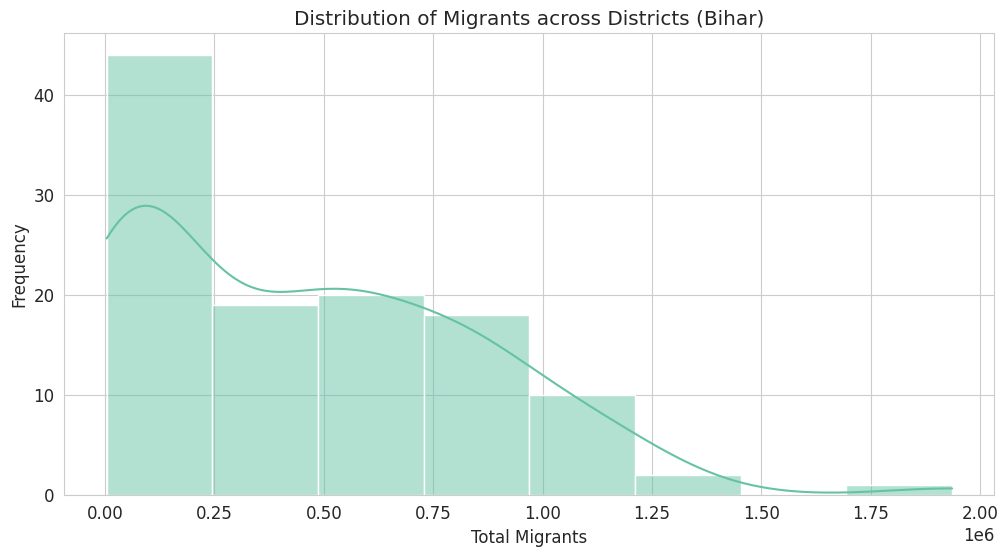

In [ ]:

plt.figure()
sns.histplot(df_core['Total_Persons'], kde=True)

plt.title('Distribution of Migrants across Districts (Bihar)')
plt.xlabel('Total Migrants')
plt.ylabel('Frequency')

plt.show()

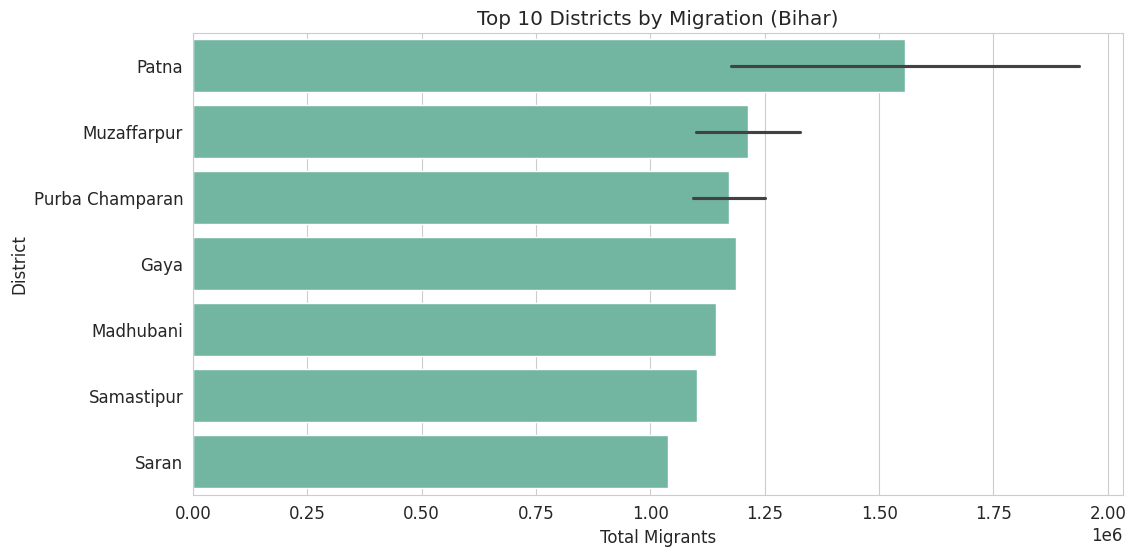

In [ ]:

top10 = df_core.sort_values(by='Total_Persons', ascending=False).head(10)

plt.figure()
sns.barplot(x='Total_Persons', y='Area_Name', data=top10)

plt.title('Top 10 Districts by Migration (Bihar)')
plt.xlabel('Total Migrants')
plt.ylabel('District')

plt.show()

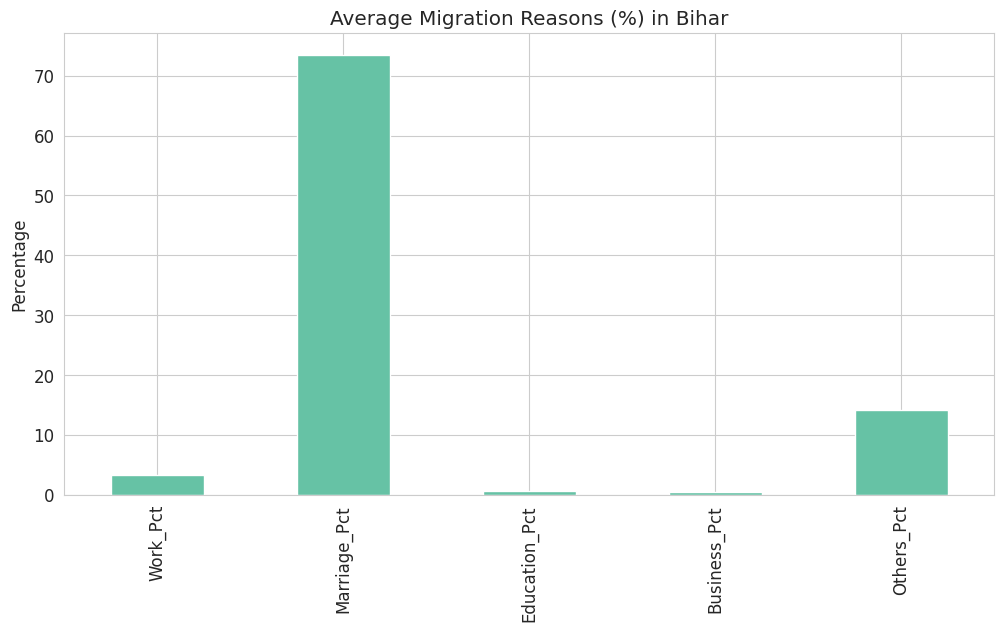

In [ ]:

reasons = ['Work_Pct', 'Marriage_Pct', 'Education_Pct', 'Business_Pct', 'Others_Pct']

df_core[reasons].mean().plot(kind='bar'

plt.title('Average Migration Reasons (%) in Bihar')
plt.ylabel('Percentage')

plt.show()

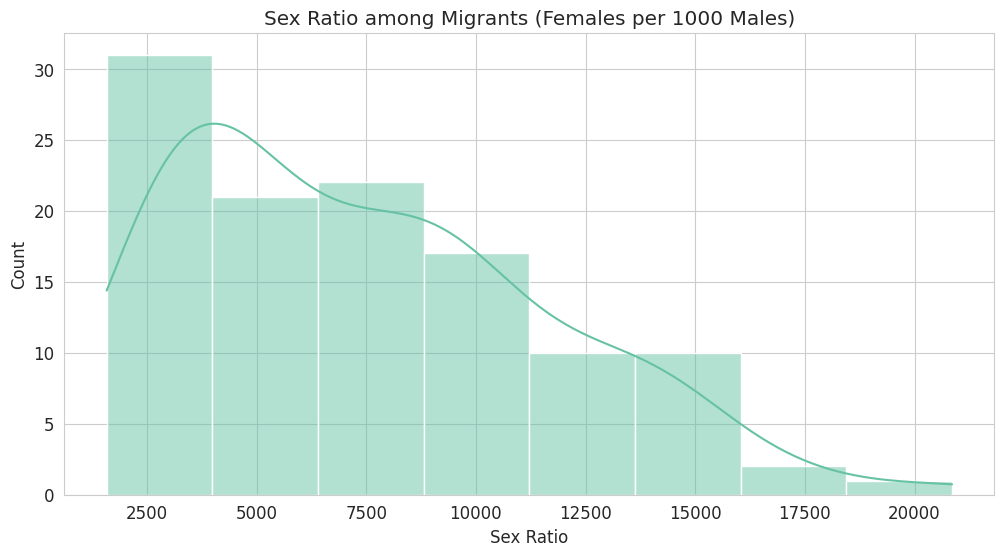

In [ ]:


plt.figure()
sns.histplot(df_core['Sex_Ratio'], kde=True)

plt.title('Sex Ratio among Migrants (Females per 1000 Males)')
plt.xlabel('Sex Ratio')

plt.show()

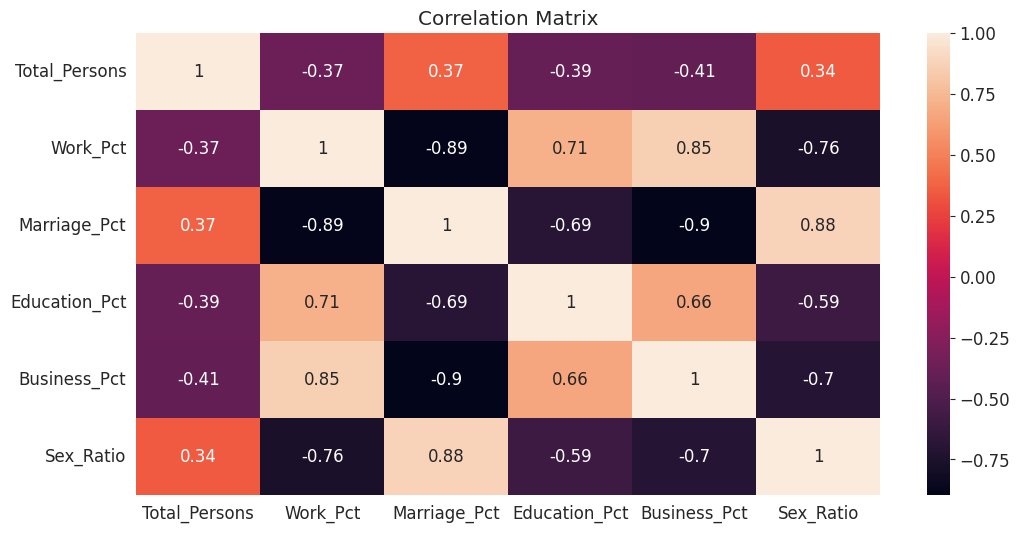

In [ ]:

corr_cols = [
    'Total_Persons','Work_Pct','Marriage_Pct',
    'Education_Pct','Business_Pct','Sex_Ratio'
]

corr = df_core[corr_cols].corr()

plt.figure()
sns.heatmap(corr, annot=True)

plt.title('Correlation Matrix')

plt.show()

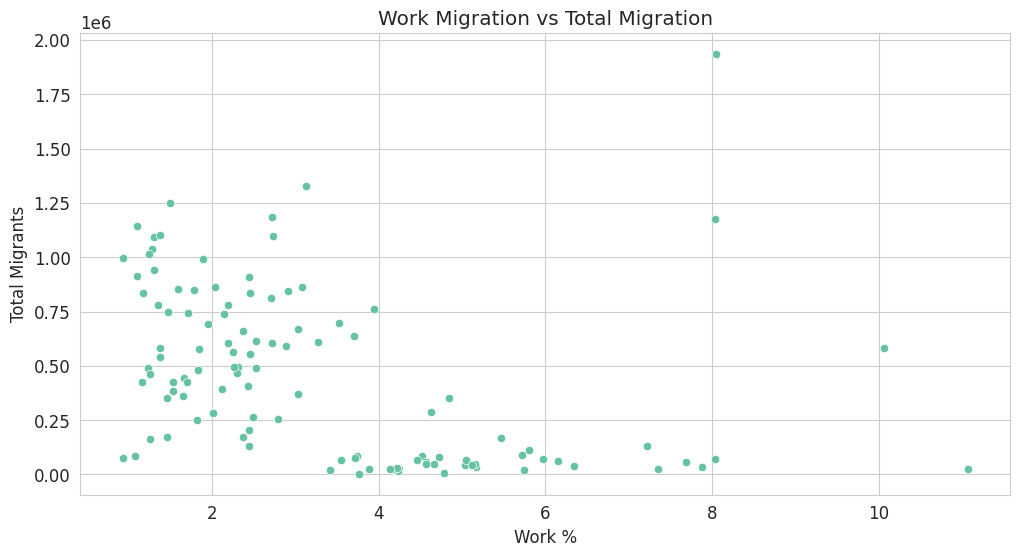

In [ ]:

plt.figure()
sns.scatterplot(x='Work_Pct', y='Total_Persons', data=df_core)

plt.title('Work Migration vs Total Migration')
plt.xlabel('Work %')
plt.ylabel('Total Migrants')

plt.show()